# 02 — Predicting BENIGN / MALIGN from radiomics and tabular data

**Mục tiêu:** ghép radiomics với metadata, xử lý đặc trưng trong từng fold, huấn luyện mô hình và đánh giá trên bệnh nhân chưa xuất hiện trong tập phát triển.

Run notebook 01 first. The target is the dataset's **radiologist-vote-derived diagnosis**: BENIGN = 0, MALIGN = 1. It is not a pathology-confirmed cancer endpoint. Predictions require a nodule VOI and mask, and also the tabular descriptors when the selected model uses them.

Compare three feature sets on the **same eligible nodules and patient folds**: tabular, radiomics, and combined. Reserve approximately 20% of patients with a fixed grouped split. Use development-only grouped cross-validation for model/hyperparameter selection. Evaluate the single selected model once on the held-out test patients, at a prespecified threshold of 0.5. The test set is never used to tune features, settings, thresholds or models.

Outputs: joined dataset, exclusion audit, patient split, cross-validation results, test predictions/metrics/figures, model bundle and inference example in `artifacts/modeling/`.

## 1. Load feature artifacts and verify provenance

In [1]:
from pathlib import Path
import os
import json
import hashlib
import importlib.metadata as metadata
from datetime import datetime, timezone
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib
import SimpleITK as sitk
import radiomics
from radiomics import featureextractor
from IPython.display import display
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.feature_selection import VarianceThreshold, SelectPercentile, f_classif
from sklearn.model_selection import StratifiedGroupKFold, GridSearchCV
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (
    roc_auc_score, average_precision_score, accuracy_score, balanced_accuracy_score,
    precision_score, recall_score, f1_score, brier_score_loss, confusion_matrix,
    classification_report, RocCurveDisplay, PrecisionRecallDisplay, ConfusionMatrixDisplay,
)

ROOT = Path.cwd().resolve()
if not (ROOT / 'MetadatabyNoduleMaxVoting.xlsx').exists() and (ROOT.parent / 'MetadatabyNoduleMaxVoting.xlsx').exists():
    ROOT = ROOT.parent
OUTPUT_SUBDIR = os.environ.get('LUNA_OUTPUT_SUBDIR', '')
assert OUTPUT_SUBDIR in ('', 'smoke')
ARTIFACTS = ROOT / 'artifacts' / OUTPUT_SUBDIR
RAD_OUT = ARTIFACTS / 'radiomics'
OUT = ARTIFACTS / 'modeling'
OUT.mkdir(parents=True, exist_ok=True)
KEYS = ['patient_id', 'nodule_id', 'seriesuid']
SEED = 42
SMOKE = os.environ.get('LUNA_SMOKE', '0') == '1'
THRESHOLD = 0.5  # Fixed before inspecting test outcomes.

def sha256_file(path):
    return hashlib.sha256(Path(path).read_bytes()).hexdigest()

assert (RAD_OUT / 'extraction_run.json').exists(), 'Run notebook 01 first.'
extraction_info = json.loads((RAD_OUT / 'extraction_run.json').read_text(encoding='utf-8'))
assert extraction_info['complete_run'] or (SMOKE and OUTPUT_SUBDIR == 'smoke'), 'Do not train the full experiment on a partial extraction.'
assert sha256_file(ROOT / 'MetadatabyNoduleMaxVoting.xlsx') == extraction_info['metadata_sha256'], 'Metadata changed: rerun notebook 01.'
assert sha256_file(RAD_OUT / 'radiomics_features.csv') == extraction_info['features_sha256'], 'Feature artifact changed: rerun notebook 01.'
assert sha256_file(RAD_OUT / 'qc.csv') == extraction_info['qc_sha256'], 'QC artifact changed: rerun notebook 01.'
assert sha256_file(RAD_OUT / 'radiomics_params.yaml') == extraction_info['params_sha256']
nodules = pd.read_excel(ROOT / 'MetadatabyNoduleMaxVoting.xlsx', dtype={'patient_id': str, 'seriesuid': str})
annotations = pd.read_excel(ROOT / 'MetadatabyAnnotation.xlsx', dtype={'patient_id': str, 'seriesuid': str})
rad = pd.read_csv(RAD_OUT / 'radiomics_features.csv', dtype={'patient_id': str, 'seriesuid': str})
qc = pd.read_csv(RAD_OUT / 'qc.csv', dtype={'patient_id': str, 'seriesuid': str})
assert not nodules.duplicated(KEYS).any() and not rad.duplicated(KEYS).any()
assert not qc.duplicated(KEYS).any()
assert len(rad) == extraction_info['n_successful']
assert rad['image'].is_unique
print('Extraction protocol:', extraction_info['protocol_id'][:16])
print('Radiomics rows/features:', len(rad), extraction_info['n_features'])

Extraction protocol: a36abcd061751894
Radiomics rows/features: 994 107


## 2. Audit target construction and join tables

This export labels a nodule MALIGN when **at least two annotation rows have `Malignancy_value > 3`**. Verify this rule against the saved labels using all three join keys. The saved aggregated malignancy score alone cannot reconstruct every label; scores of 3 are not automatically removed. Annotation groups from another CT series must not be attached to the wrong nodule.

The annotation table is used only for this audit. Exclude `Diagnosis`, `Diagnosis_value`, `Malignancy`, `Malignancy_value`, all malignancy summaries/votes and `len_mal_details` from predictors. Patient/scan/nodule identities, filenames and absolute coordinates are also excluded. No age/sex or clinical-history columns are available in these tables.

In [2]:
label_map = {'benign': 0, 'malign': 1}
nodules['target'] = nodules['Diagnosis'].str.strip().str.lower().map(label_map)
assert nodules['target'].notna().all()
assert nodules['target'].eq(nodules['Diagnosis_value']).all()
assert annotations['Malignancy_value'].isin([1, 2, 3, 4, 5]).all()
votes = annotations.assign(high_vote=annotations['Malignancy_value'].gt(3)).groupby(KEYS).agg(
    annotation_count=('Malignancy_value', 'size'), high_votes=('high_vote', 'sum')
).reset_index()
audit = nodules[KEYS + ['target', 'len_mal_details']].merge(votes, on=KEYS, how='left', validate='one_to_one')
assert audit['annotation_count'].notna().all(), 'Missing annotation group.'
assert audit['target'].eq(audit['high_votes'].ge(2).astype(int)).all(), 'Target voting rule mismatch.'
assert audit['annotation_count'].eq(audit['len_mal_details']).all()
extra_groups = votes.merge(nodules[KEYS], on=KEYS, how='left', validate='one_to_one', indicator=True)
print('Verified labels:', len(audit), '| extra annotation groups:', extra_groups['_merge'].eq('left_only').sum())
audit.to_csv(OUT / 'label_audit.csv', index=False)

data = nodules.merge(rad, on=KEYS, how='inner', validate='one_to_one').sort_values(KEYS).reset_index(drop=True)
assert len(data) == len(rad), 'Radiomics contains keys absent from metadata.'
expected_names = data['patient_id'] + '_R_' + data['nodule_id'].astype(int).astype(str) + '.nii.gz'
assert data['image'].eq(expected_names).all(), 'Nodule/file mismatch.'
successful_keys = qc.loc[qc['status'].eq('ok'), KEYS]
assert len(successful_keys) == len(data)
assert data.merge(successful_keys, on=KEYS, validate='one_to_one').shape[0] == len(data)
exclusions = nodules[KEYS + ['Diagnosis']].merge(qc[KEYS + ['status', 'error']], on=KEYS, how='left', validate='one_to_one')
assert exclusions['status'].notna().all()
exclusions = exclusions.loc[~exclusions['status'].eq('ok')]
exclusions.to_csv(OUT / 'excluded_nodules.csv', index=False)
display(pd.crosstab(exclusions['status'], exclusions['Diagnosis']))
display(data.groupby('Diagnosis').agg(nodules=('nodule_id', 'size'), patients=('patient_id', 'nunique')))
data.to_csv(OUT / 'modeling_dataset.csv', index=False)

Verified labels: 996 | extra annotation groups: 1


Diagnosis,Malign
status,
missing_pair,2


,nodules,patients
Diagnosis,,
Benign,650,389
Malign,344,262


## 3. Explicit predictor allowlist

Tabular features: diameter plus the eight non-malignancy semantic descriptors. `Calcification_value` and `InternalStructure_value` are nominal codes, so one-hot encode them. The other six scores have ordered scales and are treated as numeric ordinal inputs. These ratings describe radiologists' visual assessments of the same images; the combined model assumes those assessments are available at prediction time.

These descriptors may reproduce the readers' labeling behavior. Report radiomics-only results separately and avoid interpreting performance as proof of clinical cancer diagnosis. Tabular-only comparisons use the same cohort as combined/radiomics, rather than adding the two cases with missing images.

In [3]:
TAB_NUMERIC = ['diameter_mm', 'Lobulation_value', 'Margin_value', 'Sphericity_value',
               'Spiculation_value', 'Subtlety_value', 'Texture_value']
TAB_CATEGORICAL = ['Calcification_value', 'InternalStructure_value']
RAD_COLUMNS = sorted(c for c in data.columns if c.startswith('rad_original_'))
assert len(RAD_COLUMNS) == extraction_info['n_features'] and RAD_COLUMNS
ALL_COLUMNS = TAB_NUMERIC + TAB_CATEGORICAL + RAD_COLUMNS
FORBIDDEN = set(KEYS + ['image', 'Diagnosis', 'Diagnosis_value', 'Malignancy', 'Malignancy_value', 'len_mal_details', 'target', 'high_votes', 'annotation_count'])
assert not FORBIDDEN.intersection(ALL_COLUMNS)
X = data[ALL_COLUMNS].apply(pd.to_numeric, errors='raise').replace([np.inf, -np.inf], np.nan)
y = data['target'].astype(int)
groups = data['patient_id'].astype(str)
assert set(y.unique()) == {0, 1}
FEATURE_SETS = {
    'tabular': (TAB_NUMERIC, TAB_CATEGORICAL),
    'radiomics': (RAD_COLUMNS, []),
    'combined': (TAB_NUMERIC + RAD_COLUMNS, TAB_CATEGORICAL),
}
display(pd.Series({name: len(num) + len(cat) for name, (num, cat) in FEATURE_SETS.items()}, name='raw_features').to_frame())
print('Missing predictor values:', int(X.isna().sum().sum()))

,raw_features
tabular,9
radiomics,107
combined,116


Missing predictor values: 0


## 4. Split by patient before any learned preprocessing

Use the first fold of a fixed five-fold `StratifiedGroupKFold` as the held-out test set (approximately 20% of patients; the nodule fraction can differ). A patient with both labels remains entirely in one partition. Persist nodule and patient assignments. Use fixed grouped folds within the remaining development patients for model selection, and assert patient separation and both labels in every fold.

Reference: [scikit-learn grouped cross-validation](https://scikit-learn.org/stable/modules/cross_validation.html#stratifiedgroupkfold).

In [4]:
holdout = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=SEED)
dev_idx, test_idx = next(holdout.split(X, y, groups))
assert not set(groups.iloc[dev_idx]) & set(groups.iloc[test_idx])
X_dev, X_test = X.iloc[dev_idx].copy(), X.iloc[test_idx].copy()
y_dev, y_test = y.iloc[dev_idx].copy(), y.iloc[test_idx].copy()
groups_dev, groups_test = groups.iloc[dev_idx].copy(), groups.iloc[test_idx].copy()
assert y_dev.nunique() == 2 and y_test.nunique() == 2
CV_FOLDS = 3 if SMOKE else 5
cv = StratifiedGroupKFold(n_splits=CV_FOLDS, shuffle=True, random_state=SEED + 1)
cv_splits = list(cv.split(X_dev, y_dev, groups_dev))
dev_fold = np.full(len(X_dev), -1)
for fold, (train, validation) in enumerate(cv_splits):
    assert not set(groups_dev.iloc[train]) & set(groups_dev.iloc[validation])
    assert y_dev.iloc[train].nunique() == 2 and y_dev.iloc[validation].nunique() == 2
    dev_fold[validation] = fold
assert (dev_fold >= 0).all()
splits = data[KEYS + ['image', 'Diagnosis', 'target']].copy()
splits['partition'] = 'test'
splits['development_cv_fold'] = -1
splits.loc[dev_idx, 'partition'] = 'development'
splits.loc[dev_idx, 'development_cv_fold'] = dev_fold
assert splits.groupby('patient_id')['partition'].nunique().max() == 1
assert splits.loc[splits['partition'].eq('development')].groupby('patient_id')['development_cv_fold'].nunique().max() == 1
splits.to_csv(OUT / 'split_assignments.csv', index=False)
display(splits.groupby(['partition', 'Diagnosis']).agg(nodules=('nodule_id', 'size'), patients=('patient_id', 'nunique')))

nodules  patients
partition   Diagnosis                   
development Benign         503       302
            Malign         283       215
test        Benign         147        87
            Malign          61        47

## 5. Preprocessing, feature selection and candidate models

Fit median imputation and standardization on numeric inputs, and mode imputation/one-hot encoding on nominal inputs. Remove constant encoded features, then compare keeping 50% versus all features using ANOVA ranking. Every step is **inside the scikit-learn Pipeline**, so each validation fold gets preprocessing and selected features fitted only on its training patients. Imputation preserves all-empty numeric columns until variance filtering.

Compare balanced logistic regression and balanced random forest, plus a prior-probability dummy baseline. A compact grid controls runtime; no oversampling is performed before the split. Rank candidates by mean development-fold ROC-AUC; also report average precision and balanced accuracy. The winning CV estimate is a selection estimate and can be optimistic because it selected the configuration; the held-out test provides the final evaluation.

Reference: [scikit-learn leakage prevention](https://scikit-learn.org/stable/common_pitfalls.html#data-leakage).

In [5]:
def make_pipeline(numeric, categorical, classifier):
    transformers = []
    if numeric:
        transformers.append(('numeric', Pipeline([
            ('impute', SimpleImputer(strategy='median', keep_empty_features=True)),
            ('scale', StandardScaler()),
        ]), numeric))
    if categorical:
        transformers.append(('categorical', Pipeline([
            ('impute', SimpleImputer(strategy='most_frequent', keep_empty_features=True)),
            ('encode', OneHotEncoder(handle_unknown='ignore', sparse_output=False)),
        ]), categorical))
    return Pipeline([
        ('preprocess', ColumnTransformer(transformers, remainder='drop', verbose_feature_names_out=True)),
        ('variance', VarianceThreshold()),
        ('select', SelectPercentile(score_func=f_classif, percentile=100)),
        ('classifier', classifier),
    ])

def model_candidates():
    return {
        'logistic': (
            LogisticRegression(max_iter=5000, class_weight='balanced', solver='liblinear', random_state=SEED),
            {'select__percentile': [50, 100], 'classifier__C': [0.1, 1.0, 10.0]},
        ),
        'random_forest': (
            RandomForestClassifier(n_estimators=200, class_weight='balanced', n_jobs=1, random_state=SEED),
            {'select__percentile': [50, 100], 'classifier__max_depth': [None, 6], 'classifier__min_samples_leaf': [2, 5]},
        ),
    }

SCORING = {'roc_auc': 'roc_auc', 'average_precision': 'average_precision', 'balanced_accuracy': 'balanced_accuracy'}
searches, summary_rows = {}, []
for feature_set, (numeric, categorical) in FEATURE_SETS.items():
    for model_name, (classifier, grid) in model_candidates().items():
        if SMOKE:
            grid = {name: [values[0]] for name, values in grid.items()}
        search = GridSearchCV(
            make_pipeline(numeric, categorical, classifier), param_grid=grid,
            scoring=SCORING, refit='roc_auc', cv=cv_splits,
            n_jobs=2, error_score='raise', return_train_score=False,
        )
        search.fit(X_dev, y_dev)
        searches[(feature_set, model_name)] = search
        results = pd.DataFrame(search.cv_results_)
        results.to_csv(OUT / f'cv_grid_{feature_set}_{model_name}.csv', index=False)
        best = results.iloc[search.best_index_]
        summary_rows.append({
            'feature_set': feature_set, 'model': model_name,
            'mean_cv_roc_auc': best['mean_test_roc_auc'], 'std_cv_roc_auc': best['std_test_roc_auc'],
            'mean_cv_average_precision': best['mean_test_average_precision'],
            'mean_cv_balanced_accuracy': best['mean_test_balanced_accuracy'],
            'best_params': json.dumps(search.best_params_, sort_keys=True),
        })
        print(feature_set, model_name, 'CV ROC-AUC:', round(search.best_score_, 4))

# Use exactly the same folds for the baseline.
dummy_rows = []
for train, validation in cv_splits:
    baseline = DummyClassifier(strategy='prior').fit(X_dev.iloc[train], y_dev.iloc[train])
    probabilities = baseline.predict_proba(X_dev.iloc[validation])[:, 1]
    dummy_rows.append({
        'roc_auc': roc_auc_score(y_dev.iloc[validation], probabilities),
        'average_precision': average_precision_score(y_dev.iloc[validation], probabilities),
        'balanced_accuracy': balanced_accuracy_score(y_dev.iloc[validation], baseline.predict(X_dev.iloc[validation])),
    })
dummy_cv = pd.DataFrame(dummy_rows)
summary_rows.append({
    'feature_set': 'baseline', 'model': 'dummy_prior',
    'mean_cv_roc_auc': dummy_cv['roc_auc'].mean(), 'std_cv_roc_auc': dummy_cv['roc_auc'].std(ddof=0),
    'mean_cv_average_precision': dummy_cv['average_precision'].mean(),
    'mean_cv_balanced_accuracy': dummy_cv['balanced_accuracy'].mean(), 'best_params': '{}',
})
cv_summary = pd.DataFrame(summary_rows).sort_values(['mean_cv_roc_auc', 'feature_set', 'model'], ascending=[False, True, True]).reset_index(drop=True)
cv_summary.to_csv(OUT / 'cv_summary.csv', index=False)
display(cv_summary)
eligible = cv_summary.loc[cv_summary['feature_set'].ne('baseline')]
winner = eligible.iloc[0]
WINNER_SET, WINNER_MODEL = winner['feature_set'], winner['model']
best_search = searches[(WINNER_SET, WINNER_MODEL)]
best_model = best_search.best_estimator_  # GridSearchCV refitted this on all development rows.
print('Selected before test evaluation:', WINNER_SET, WINNER_MODEL, best_search.best_params_)

tabular logistic CV ROC-AUC: 0.9367


tabular random_forest CV ROC-AUC: 0.942


radiomics logistic CV ROC-AUC: 0.925


radiomics random_forest CV ROC-AUC: 0.9271


combined logistic CV ROC-AUC: 0.9344


combined random_forest CV ROC-AUC: 0.9304


,feature_set,model,mean_cv_roc_auc,std_cv_roc_auc,mean_cv_average_precision,mean_cv_balanced_accuracy,best_params
0,tabular,random_forest,0.942029,0.014045,0.919578,0.868922,"{""classifier__max_depth"": 6, ""classifier__min_..."
1,tabular,logistic,0.936734,0.018225,0.898023,0.876972,"{""classifier__C"": 10.0, ""select__percentile"": ..."
2,combined,logistic,0.934447,0.015502,0.905503,0.872916,"{""classifier__C"": 0.1, ""select__percentile"": 50}"
3,combined,random_forest,0.930435,0.015439,0.900355,0.856370,"{""classifier__max_depth"": null, ""classifier__m..."
4,radiomics,random_forest,0.927095,0.017603,0.898192,0.845297,"{""classifier__max_depth"": null, ""classifier__m..."
5,radiomics,logistic,0.925030,0.017677,0.890000,0.842066,"{""classifier__C"": 0.1, ""select__percentile"": 50}"
6,baseline,dummy_prior,0.500000,0.000000,0.362371,0.500000,{}


Selected before test evaluation: tabular random_forest {'classifier__max_depth': 6, 'classifier__min_samples_leaf': 2, 'select__percentile': 100}


## 6. Evaluate the selected model on held-out patients

Use ROC-AUC, average precision (AP), balanced accuracy, accuracy, precision, recall/sensitivity, specificity, F1 and Brier score. AP should be interpreted relative to positive prevalence. The threshold is fixed at 0.5; class-weighted model scores are not clinically calibrated malignancy probabilities. Test labels are used here only for reporting after model selection.

Bootstrap **patients**, retaining all their nodules together and their repeat-sampling multiplicity, to estimate an approximate 95% ROC-AUC interval. Metrics remain nodule-level; this interval reflects finite test-patient sampling, not training, tuning or external-population uncertainty. Fold standard deviations above are not confidence intervals.

,selected_model,dummy_prior
roc_auc,0.959741,0.500000
average_precision,0.868862,0.293269
accuracy,0.908654,0.706731
balanced_accuracy,0.906602,0.500000
precision_malign,0.808824,0.000000
recall_sensitivity_malign,0.901639,0.000000
specificity_benign,0.911565,1.000000
f1_malign,0.852713,0.000000
brier_score,0.073416,0.211722
positive_prevalence,0.293269,0.293269


Patient-bootstrap ROC-AUC 95% interval: [0.931 0.985]
              precision    recall  f1-score   support

      BENIGN       0.96      0.91      0.93       147
      MALIGN       0.81      0.90      0.85        61

    accuracy                           0.91       208
   macro avg       0.88      0.91      0.89       208
weighted avg       0.91      0.91      0.91       208



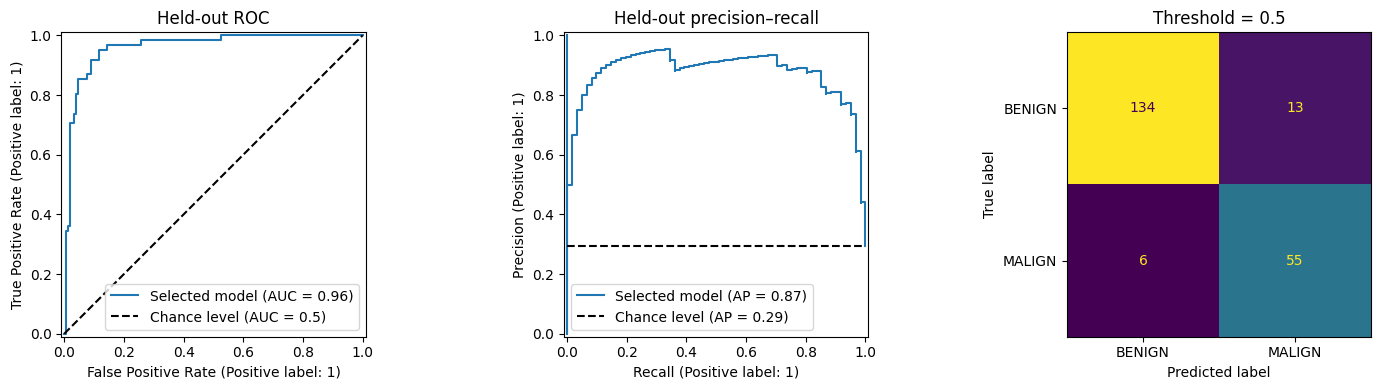

In [6]:
def binary_metrics(labels, probabilities, threshold=0.5):
    predicted = (np.asarray(probabilities) >= threshold).astype(int)
    tn, fp, fn, tp = confusion_matrix(labels, predicted, labels=[0, 1]).ravel()
    return {
        'roc_auc': float(roc_auc_score(labels, probabilities)),
        'average_precision': float(average_precision_score(labels, probabilities)),
        'accuracy': float(accuracy_score(labels, predicted)),
        'balanced_accuracy': float(balanced_accuracy_score(labels, predicted)),
        'precision_malign': float(precision_score(labels, predicted, zero_division=0)),
        'recall_sensitivity_malign': float(recall_score(labels, predicted, zero_division=0)),
        'specificity_benign': float(tn / (tn + fp)) if tn + fp else None,
        'f1_malign': float(f1_score(labels, predicted, zero_division=0)),
        'brier_score': float(brier_score_loss(labels, probabilities)),
        'positive_prevalence': float(np.mean(labels)),
        'threshold': float(threshold), 'tn': int(tn), 'fp': int(fp), 'fn': int(fn), 'tp': int(tp),
    }

test_probability = best_model.predict_proba(X_test)[:, 1]
test_prediction = (test_probability >= THRESHOLD).astype(int)
test_metrics = binary_metrics(y_test, test_probability, THRESHOLD)
baseline = DummyClassifier(strategy='prior').fit(X_dev, y_dev)
baseline_metrics = binary_metrics(y_test, baseline.predict_proba(X_test)[:, 1], THRESHOLD)
test_predictions = data.iloc[test_idx][KEYS + ['image', 'Diagnosis', 'target']].copy()
test_predictions['score_malign'] = test_probability
test_predictions['prediction'] = test_prediction
test_predictions['predicted_label'] = np.where(test_prediction == 1, 'MALIGN', 'BENIGN')
test_predictions.to_csv(OUT / 'test_predictions.csv', index=False)

def patient_bootstrap_auc(labels, probabilities, patient_ids, repeats=1000):
    labels, probabilities = np.asarray(labels), np.asarray(probabilities)
    patient_ids = np.asarray(patient_ids)
    patients = np.unique(patient_ids)
    members = {patient: np.flatnonzero(patient_ids == patient) for patient in patients}
    rng = np.random.default_rng(SEED)
    aucs = []
    for _ in range(repeats):
        sampled_patients = rng.choice(patients, size=len(patients), replace=True)
        sampled_rows = np.concatenate([members[patient] for patient in sampled_patients])
        if np.unique(labels[sampled_rows]).size == 2:
            aucs.append(roc_auc_score(labels[sampled_rows], probabilities[sampled_rows]))
    assert aucs, 'No bootstrap replicate contained both labels.'
    return [float(value) for value in np.percentile(aucs, [2.5, 97.5])], len(aucs)

auc_interval, valid_bootstraps = patient_bootstrap_auc(y_test, test_probability, groups_test, repeats=100 if SMOKE else 1000)
report = {
    'feature_set': WINNER_SET, 'model': WINNER_MODEL, 'best_params': best_search.best_params_,
    'development_cv_roc_auc_selection_estimate': float(best_search.best_score_),
    'test_metrics': test_metrics, 'dummy_test_metrics': baseline_metrics,
    'test_roc_auc_patient_bootstrap_95_ci': auc_interval, 'valid_bootstrap_replicates': valid_bootstraps,
    'development_nodules': len(X_dev), 'test_nodules': len(X_test),
    'development_patients': groups_dev.nunique(), 'test_patients': groups_test.nunique(),
    'seed': SEED, 'smoke_run': SMOKE,
}
(OUT / 'test_metrics.json').write_text(json.dumps(report, indent=2), encoding='utf-8')
display(pd.DataFrame({'selected_model': test_metrics, 'dummy_prior': baseline_metrics}))
print('Patient-bootstrap ROC-AUC 95% interval:', np.round(auc_interval, 3))
print(classification_report(y_test, test_prediction, labels=[0, 1], target_names=['BENIGN', 'MALIGN'], zero_division=0))
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
RocCurveDisplay.from_predictions(y_test, test_probability, ax=axes[0], name='Selected model', plot_chance_level=True)
PrecisionRecallDisplay.from_predictions(y_test, test_probability, ax=axes[1], name='Selected model', plot_chance_level=True)
ConfusionMatrixDisplay.from_predictions(y_test, test_prediction, labels=[0, 1], display_labels=['BENIGN', 'MALIGN'], ax=axes[2], colorbar=False)
for ax, title in zip(axes, ['Held-out ROC', 'Held-out precision–recall', 'Threshold = 0.5']):
    ax.set_title(title)
plt.tight_layout()
plt.savefig(OUT / 'test_evaluation.png', dpi=150, bbox_inches='tight')
plt.show()

## 7. Inspect selected features and save the fitted model

Recover names after one-hot encoding, variance filtering and feature selection. Logistic coefficients are expressed after numeric standardization; forest impurity importances can favor continuous features. Correlated predictors can share effects, so these rankings describe the fitted model rather than causal or stable biomarkers. Neither rankings nor test errors are used to revise the evaluated model.

Save the development-fitted pipeline, its raw-input schema, fixed threshold, extraction settings and package versions. Keep the test patients out of this model so the saved artifact matches the reported evaluation. Save only built-in scikit-learn transformers, allowing reload in another Python process without custom notebook classes.

,feature,impurity_importance,absolute_effect
0,numeric__diameter_mm,0.511362,0.511362
5,numeric__Subtlety_value,0.185528,0.185528
4,numeric__Spiculation_value,0.081938,0.081938
1,numeric__Lobulation_value,0.062489,0.062489
12,categorical__Calcification_value_6,0.043482,0.043482
9,categorical__Calcification_value_3,0.036159,0.036159
2,numeric__Margin_value,0.035601,0.035601
6,numeric__Texture_value,0.021574,0.021574
3,numeric__Sphericity_value,0.016222,0.016222
8,categorical__Calcification_value_2,0.005241,0.005241


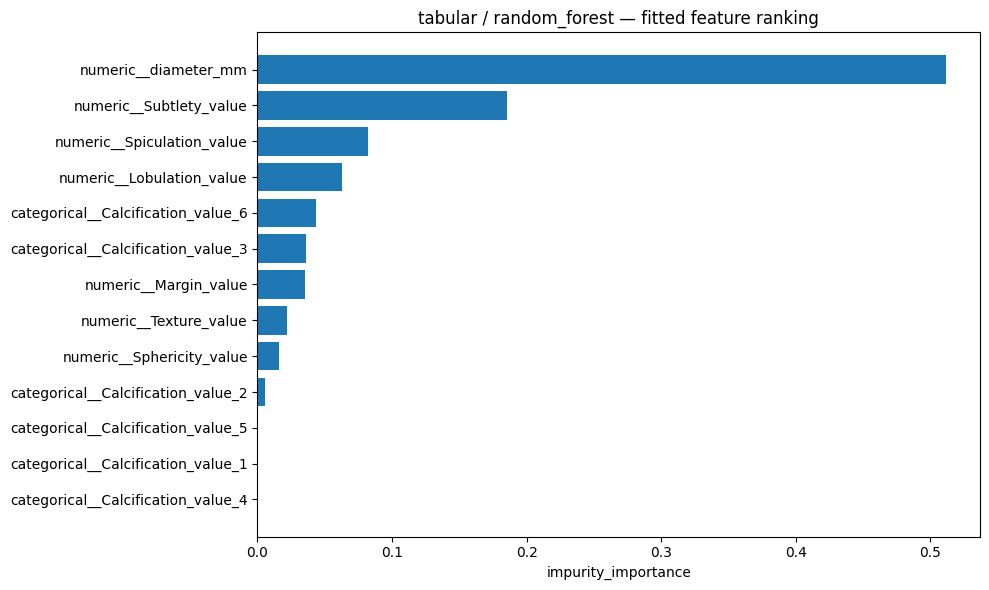

Model saved and reload predictions verified: D:\Github\LUNA-lung-cancer-analysis\artifacts\modeling\malign_benign_model.joblib


Saved tabular, radiomics and combined development-fitted model bundles.


In [7]:
encoded_names = np.asarray(best_model.named_steps['preprocess'].get_feature_names_out())
nonconstant_names = encoded_names[best_model.named_steps['variance'].get_support()]
selected_names = nonconstant_names[best_model.named_steps['select'].get_support()]
classifier = best_model.named_steps['classifier']
if hasattr(classifier, 'coef_'):
    effects = classifier.coef_[0]
    effect_name = 'coefficient'
else:
    effects = classifier.feature_importances_
    effect_name = 'impurity_importance'
importance = pd.DataFrame({'feature': selected_names, effect_name: effects})
importance['absolute_effect'] = np.abs(effects)
importance = importance.sort_values('absolute_effect', ascending=False)
importance.to_csv(OUT / 'selected_feature_importance.csv', index=False)
display(importance.head(20))
top = importance.head(15).iloc[::-1]
fig, ax = plt.subplots(figsize=(10, 6))
ax.barh(top['feature'], top[effect_name])
ax.set_xlabel(effect_name)
ax.set_title(f'{WINNER_SET} / {WINNER_MODEL} — fitted feature ranking')
plt.tight_layout()
plt.savefig(OUT / 'feature_ranking.png', dpi=150, bbox_inches='tight')
plt.show()

numeric, categorical = FEATURE_SETS[WINNER_SET]
required_inputs = numeric + categorical
MODEL_VERSIONS = {name: metadata.version(name) for name in ['numpy', 'pandas', 'scikit-learn', 'joblib', 'SimpleITK', 'pyradiomics', 'PyWavelets']}
bundle = {
    'pipeline': best_model, 'required_inputs': required_inputs, 'feature_set': WINNER_SET,
    'model': WINNER_MODEL, 'threshold': THRESHOLD, 'label_mapping': {0: 'BENIGN', 1: 'MALIGN'},
    'selected_features': selected_names.tolist(), 'versions': MODEL_VERSIONS,
    'radiomics_protocol_id': extraction_info['protocol_id'],
    'radiomics_params_yaml': (RAD_OUT / 'radiomics_params.yaml').read_text(encoding='utf-8'),
    'preprocess_revision': extraction_info['preprocess_revision'],
    'fitted_partition': 'development',
    'target_definition': 'At least two annotation rows with Malignancy_value > 3; radiologist assessment, not pathology',
}
model_path = OUT / 'malign_benign_model.joblib'
joblib.dump(bundle, model_path)
reloaded = joblib.load(model_path)
np.testing.assert_allclose(reloaded['pipeline'].predict_proba(X_test)[:, 1], test_probability)
schema = {key: value for key, value in bundle.items() if key not in ['pipeline', 'radiomics_params_yaml']}
schema['created_at_utc'] = datetime.now(timezone.utc).isoformat()
schema['extraction_features_sha256'] = extraction_info['features_sha256']
schema['annotation_table_sha256'] = sha256_file(ROOT / 'MetadatabyAnnotation.xlsx')
schema['split_sha256'] = sha256_file(OUT / 'split_assignments.csv')
(OUT / 'model_schema.json').write_text(json.dumps(schema, indent=2), encoding='utf-8')
print('Model saved and reload predictions verified:', model_path)

# Save the CV-selected model for each feature set, including a combined model
# even when another feature set wins. These receive no extra test evaluation.
arm_bundles = {}
for feature_set in FEATURE_SETS:
    arm_winner = eligible.loc[eligible['feature_set'].eq(feature_set)].iloc[0]
    arm_search = searches[(feature_set, arm_winner['model'])]
    arm_model = arm_search.best_estimator_
    names = np.asarray(arm_model.named_steps['preprocess'].get_feature_names_out())
    names = names[arm_model.named_steps['variance'].get_support()]
    names = names[arm_model.named_steps['select'].get_support()]
    arm_numeric, arm_categorical = FEATURE_SETS[feature_set]
    arm_bundle = {
        **bundle, 'pipeline': arm_model, 'feature_set': feature_set,
        'model': arm_winner['model'], 'required_inputs': arm_numeric + arm_categorical,
        'selected_features': names.tolist(),
    }
    joblib.dump(arm_bundle, OUT / f'{feature_set}_best_model.joblib')
    arm_bundles[feature_set] = arm_bundle
print('Saved tabular, radiomics and combined development-fitted model bundles.')

## 8. Inference from a VOI/mask pair and tabular descriptors

This example re-extracts features from one existing held-out nodule to verify end-to-end prediction parity. It is a demonstration, not an additional independent evaluation. For a new nodule, replace the two file paths and supply the available tabular descriptor values. A radiomics-only model needs no tabular values; a combined/tabular model requires all tabular input columns. Missing **values** can be imputed, but missing required **columns** trigger an error.

Use the exact saved extraction settings and compatible package versions. Masks must already align physically with the image and use label 1 for the nodule. The baseline allows every labeled component and rejects invalid geometry, nonbinary masks and insufficient ROIs. Joblib files should be loaded only from a trusted source.

In [8]:
def predict_feature_rows(model_bundle, rows):
    frame = pd.DataFrame(rows).copy()
    missing = set(model_bundle['required_inputs']) - set(frame.columns)
    if missing:
        raise ValueError('Missing required input columns: ' + ', '.join(sorted(missing)))
    frame = frame[model_bundle['required_inputs']].apply(pd.to_numeric, errors='raise').replace([np.inf, -np.inf], np.nan)
    probabilities = model_bundle['pipeline'].predict_proba(frame)[:, 1]
    predicted = (probabilities >= model_bundle['threshold']).astype(int)
    return pd.DataFrame({'score_malign': probabilities, 'predicted_label': [model_bundle['label_mapping'][int(value)] for value in predicted]})

def predict_voi(model_bundle, image_path, mask_path, tabular_values=None):
    for package in ['numpy', 'SimpleITK', 'pyradiomics', 'PyWavelets', 'scikit-learn']:
        if metadata.version(package) != model_bundle['versions'][package]:
            raise RuntimeError(f'Package version mismatch for {package}; use requirements-radiomics.txt')
    values = dict(tabular_values or {})
    needs_radiomics = any(name.startswith('rad_') for name in model_bundle['required_inputs'])
    if needs_radiomics:
        image = sitk.ReadImage(str(image_path), sitk.sitkFloat32)
        mask = sitk.ReadImage(str(mask_path))
        if image.GetDimension() != 3 or mask.GetDimension() != 3 or image.GetSize() != mask.GetSize():
            raise ValueError('Expected matching 3D image/mask dimensions')
        for attr in ['GetSpacing', 'GetOrigin', 'GetDirection']:
            if not np.allclose(getattr(image, attr)(), getattr(mask, attr)(), atol=1e-6, rtol=0):
                raise ValueError('Image/mask geometry mismatch: ' + attr)
        image_values = sitk.GetArrayFromImage(image)
        labels = sitk.GetArrayFromImage(mask)
        if not np.isfinite(image_values).all() or not np.isfinite(labels).all() or not np.isin(labels, [0, 1]).all():
            raise ValueError('Non-finite values or nonbinary mask')
        roi = labels == 1
        if roi.sum() < 8 or ((np.ptp(np.argwhere(roi), axis=0) + 1) > 1).sum() < 2:
            raise ValueError('Insufficient nodule ROI')
        image = sitk.DICOMOrient(image, 'LPS')
        mask = sitk.DICOMOrient(sitk.Cast(mask, sitk.sitkUInt8), 'LPS')
        import yaml
        inference_extractor = featureextractor.RadiomicsFeatureExtractor(yaml.safe_load(model_bundle['radiomics_params_yaml']))
        extracted = inference_extractor.execute(image, mask, label=1)
        for name, value in extracted.items():
            if name.startswith('original_'):
                values['rad_' + name] = float(np.asarray(value).item())
    return predict_feature_rows(model_bundle, [values])

example = data.iloc[test_idx[0]]
tabular_example = example[TAB_NUMERIC + TAB_CATEGORICAL].to_dict()
prediction_from_voi = predict_voi(
    reloaded,
    ROOT / 'VOIs' / 'VOIs' / 'image' / example['image'],
    ROOT / 'VOIs' / 'VOIs' / 'nodule_mask' / example['image'],
    tabular_example,
)
np.testing.assert_allclose(prediction_from_voi['score_malign'].iloc[0], test_probability[0], rtol=1e-6, atol=1e-8)
display(prediction_from_voi)
print('Selected saved-model prediction matches the feature-table prediction.')

# Always exercise the complete radiomics + tabular path, including when the
# overall CV winner uses only tabular inputs. This checks parity, not accuracy.
combined_bundle = joblib.load(OUT / 'combined_best_model.joblib')
combined_prediction = predict_voi(
    combined_bundle,
    ROOT / 'VOIs' / 'VOIs' / 'image' / example['image'],
    ROOT / 'VOIs' / 'VOIs' / 'nodule_mask' / example['image'],
    tabular_example,
)
combined_expected = combined_bundle['pipeline'].predict_proba(X_test.iloc[[0]])[:, 1]
np.testing.assert_allclose(combined_prediction['score_malign'], combined_expected, rtol=1e-6, atol=1e-8)
display(combined_prediction)
print('Combined model: raw VOI + mask + tabular values reproduce the stored-feature prediction.')

,score_malign,predicted_label
0,0.963808,MALIGN


Selected saved-model prediction matches the feature-table prediction.


GLCM is symmetrical, therefore Sum Average = 2 * Joint Average, only 1 needs to be calculated


,score_malign,predicted_label
0,0.992881,MALIGN


Combined model: raw VOI + mask + tabular values reproduce the stored-feature prediction.


## 9. Report the experiment

Record the successful/excluded nodule counts, extraction protocol, patient partitions, feature sets, candidate grids and selected configuration. Report test ROC-AUC with the patient-bootstrap interval, AP, sensitivity, specificity and the confusion matrix at threshold 0.5. CV compares the three feature sets; only the development-selected winner is evaluated on test patients. This does not provide a held-out test comparison of every feature set.

Limits: radiologist-derived labels, correlated semantic descriptors, unverified intensity calibration, small/disconnected ROIs, fixed single split and one dataset. Generalization to pathology-confirmed cancer, other hospitals or new acquisition protocols requires a separate validation study. Repeatedly revising this pipeline after viewing test results would turn these patients into development data and require a fresh independent test set.

Do not refit on the test set or choose a new threshold from the plots when reporting the saved model's evaluation.

In [9]:
summary = (
    f"Selected {WINNER_SET} / {WINNER_MODEL} on development CV. "
    f"Held-out test: {len(X_test)} nodules from {groups_test.nunique()} patients; "
    f"ROC-AUC {test_metrics['roc_auc']:.3f} "
    f"(patient-bootstrap 95% interval {auc_interval[0]:.3f}–{auc_interval[1]:.3f}); "
    f"AP {test_metrics['average_precision']:.3f}; "
    f"sensitivity {test_metrics['recall_sensitivity_malign']:.3f}; "
    f"specificity {test_metrics['specificity_benign']:.3f} at threshold {THRESHOLD}."
)
print(summary)
(OUT / 'experiment_summary.txt').write_text(summary + '\n', encoding='utf-8')
print('Artifacts:', OUT)

Selected tabular / random_forest on development CV. Held-out test: 208 nodules from 116 patients; ROC-AUC 0.960 (patient-bootstrap 95% interval 0.931–0.985); AP 0.869; sensitivity 0.902; specificity 0.912 at threshold 0.5.
Artifacts: D:\Github\LUNA-lung-cancer-analysis\artifacts\modeling
